# Crime Patterns in Los Angeles

Exploratory analysis of ~185,000 crime records from the Los Angeles Police Department (LAPD) to support resource allocation. It answers three questions:

1. Which hour of the day has the most crimes?
2. Which area has the most night-time crimes (10 pm to 3:59 am)?
3. How are crimes distributed across victim age groups?

**Data:** `crimes.csv`, a modified version of the public [Los Angeles Open Data](https://data.lacity.org/) crime records (see [`../data/README.md`](../data/README.md)).

In [1]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../data/"

crimes = pd.read_csv(DATA_DIR + "crimes.csv", dtype={"TIME OCC": str})
crimes.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA NAME,Crm Cd Desc,Vict Age,Vict Sex,Vict Descent,Weapon Desc,Status Desc,LOCATION
0,220314085,2022-07-22,2020-05-12,1110,Southwest,THEFT OF IDENTITY,27,F,B,NaN,Invest Cont,2500 S SYCAMORE AV
1,222013040,2022-08-06,2020-06-04,1620,Olympic,THEFT OF IDENTITY,60,M,H,NaN,Invest Cont,3300 SAN MARINO ST
2,220614831,2022-08-18,2020-08-17,1200,Hollywood,THEFT OF IDENTITY,28,M,H,NaN,Invest Cont,1900 TRANSIENT
3,231207725,2023-02-27,2020-01-27,0635,77th Street,THEFT OF IDENTITY,37,M,H,NaN,Invest Cont,6200 4TH AV
4,220213256,2022-07-14,2020-07-14,0900,Rampart,THEFT OF IDENTITY,79,M,B,NaN,Invest Cont,1200 W 7TH ST


In [2]:
crimes.shape

(185715, 12)

In [3]:
crimes.dtypes

DR_NO            int64
Date Rptd       object
DATE OCC        object
TIME OCC        object
AREA NAME       object
Crm Cd Desc     object
Vict Age         int64
Vict Sex        object
Vict Descent    object
Weapon Desc     object
Status Desc     object
LOCATION        object
dtype: object

## 1. Convert dates and times

In [4]:
crimes['Date Rptd'] = pd.to_datetime(crimes['Date Rptd'])
crimes['DATE OCC'] = pd.to_datetime(crimes['DATE OCC'])
crimes['TIME OCC'] = pd.to_datetime(crimes['TIME OCC'], format='%H%M')
crimes[['Date Rptd', 'DATE OCC', 'TIME OCC']].dtypes

Date Rptd    datetime64[ns]
DATE OCC     datetime64[ns]
TIME OCC     datetime64[ns]
dtype: object

## 2. Peak crime hour

In [5]:
# Hour with the highest number of crimes, as an integer called peak_crime_hour
crimes['TIME hour'] = crimes['TIME OCC'].dt.hour
peak_crime_hour = crimes['TIME hour'].value_counts().idxmax()
peak_crime_hour

np.int32(12)

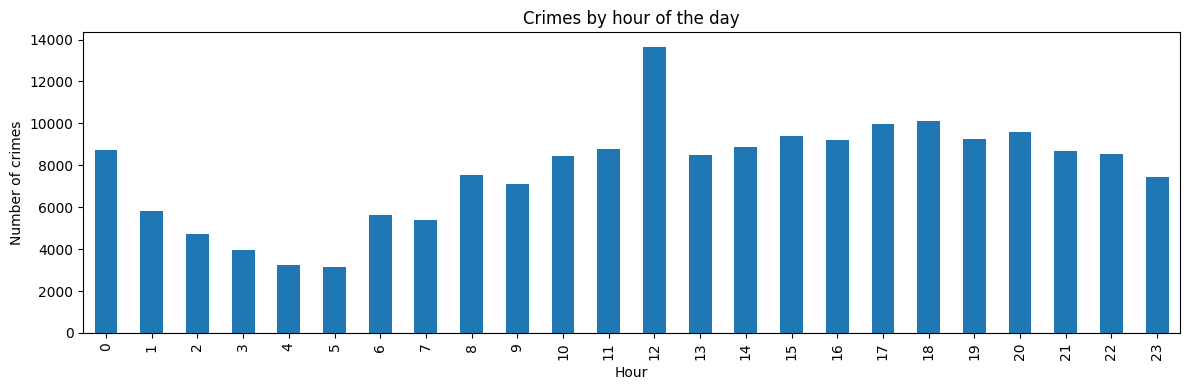

In [6]:
crimes['TIME hour'].value_counts().sort_index().plot(kind='bar', figsize=(12, 4))
plt.title('Crimes by hour of the day')
plt.xlabel('Hour')
plt.ylabel('Number of crimes')
plt.tight_layout()
plt.show()

## 3. Area with the most night-time crimes

In [7]:
# Area with the most crimes between 10 pm and 3:59 am, as a string called peak_night_crime_location
nocturnal_crime = crimes[(crimes['TIME hour'] >= 22) | (crimes['TIME hour'] < 4)]
peak_night_crime_location = nocturnal_crime['AREA NAME'].value_counts().idxmax()
peak_night_crime_location

'Central'

## 4. Crimes by victim age group

In [8]:
# Number of crimes per victim age group, as a Series called victim_ages
age_categories = ["0-17", "18-25", "26-34", "35-44", "45-54", "55-64", "65+"]

age_ranges = [-1, 17, 25, 34, 44, 54, 64, crimes['Vict Age'].max()]

crimes['categories_ages'] = pd.cut(crimes['Vict Age'], bins=age_ranges, labels=age_categories)
victim_ages = crimes['categories_ages'].value_counts()
victim_ages

categories_ages
26-34    47470
35-44    42157
45-54    28353
18-25    28291
55-64    20169
65+      14747
0-17      4528
Name: count, dtype: int64

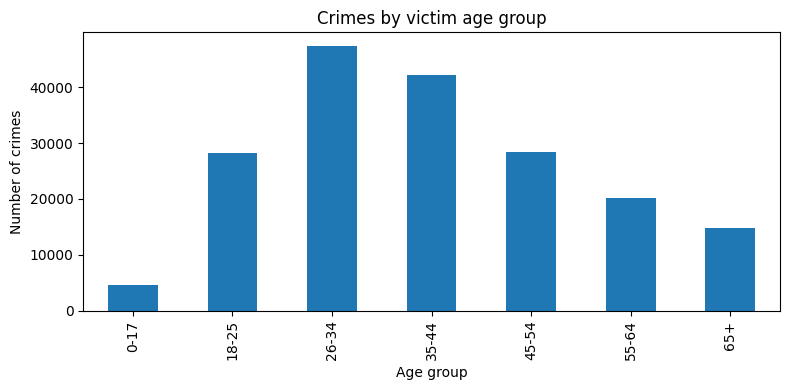

In [9]:
victim_ages.sort_index().plot(kind='bar', figsize=(8, 4))
plt.title('Crimes by victim age group')
plt.xlabel('Age group')
plt.ylabel('Number of crimes')
plt.tight_layout()
plt.show()